# ДЗ 4, часть 1: RAG на своём корпусе (переделка ДЗ 2 по фидбеку)

Корпус: русская Википедия о событиях сентября 2026 года, откуда взяты свои вопросы `fresh-125` … `fresh-144` из ДЗ 1
(`fetch_corpus_ru.py`). Вопросы: эти двадцать плюс 97 вопросов по строкам корпуса (`make_questions.py`),
десять своих вопросов без ответа.

Milvus: по умолчанию сервер из `docker-compose.yml` (`http://localhost:19530`); без Docker можно указать файл
Milvus Lite, например `HW4_MILVUS_URI=./milvus_hw4.db` (работает на Linux и macOS, на Windows через WSL).

In [1]:
import os, re, sys, json, time, hashlib, threading
from pathlib import Path
from dataclasses import dataclass, field
from concurrent.futures import ThreadPoolExecutor
from typing import Literal
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field
from pymilvus import MilvusClient

try:
    from dotenv import load_dotenv
    load_dotenv(Path("..") / ".env")
    load_dotenv()
except ImportError:
    pass
assert os.getenv("OPENROUTER_API_KEY"), "нет ключа: положите OPENROUTER_API_KEY в .env в корне репозитория"

CHAT_URL = "https://openrouter.ai/api/v1/chat/completions"
EMBED_URL = "https://openrouter.ai/api/v1/embeddings"
HEADERS = {"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}", "X-Title": "agents-course-hw4"}
MODELS = {"cheap": "openai/gpt-4o-mini", "mid": "anthropic/claude-haiku-4.5", "strong": "anthropic/claude-sonnet-4.6"}
EMBED_MODEL, DIM = "openai/text-embedding-3-small", 512
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}
DATA = Path("data")
Path("img").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)


@dataclass
class Ledger:
    calls: list = field(default_factory=list)
    local: threading.local = field(default_factory=threading.local)

    def add(self, tag, model, usage, seconds=0.0):
        cost = usage.get("cost") or 0.0
        self.calls.append({"tag": tag, "model": model.split("/")[-1], "prompt": usage.get("prompt_tokens", 0),
                           "completion": usage.get("completion_tokens", 0), "cost": cost, "seconds": round(seconds, 2)})
        self.local.spent = self.mine + cost
        return cost

    @property
    def total(self):
        return sum(c["cost"] for c in self.calls)

    @property
    def mine(self):
        return getattr(self.local, "spent", 0.0)

    def table(self):
        frame = pd.DataFrame(self.calls, columns=["tag", "model", "prompt", "completion", "cost", "seconds"])
        return frame.groupby(["tag", "model"]).agg(calls=("cost", "size"), prompt=("prompt", "sum"),
                                                   completion=("completion", "sum"), cost=("cost", "sum")).round(5)


ledger = Ledger()


def post_with_retry(url, body, attempts=5):
    problem = "нет ответа"
    for attempt in range(attempts):
        try:
            r = requests.post(url, json=body, headers=HEADERS, timeout=120)
            if r.status_code == 200:
                return r.json()
            problem = f"HTTP {r.status_code}: {r.text[:200]}"
            if r.status_code not in (429, 500, 502, 503, 504):
                break
        except requests.RequestException as e:
            problem = type(e).__name__
        time.sleep(2.0 * (attempt + 1))
    raise RuntimeError(problem)


def chat(messages, model, tools=None, tag="chat"):
    # max_tokens явно: без него OpenRouter резервирует под Sonnet 64 тысячи токенов и отказывает при малом остатке на ключе
    body = {"model": model, "messages": messages, "temperature": 0, "max_tokens": 1024, "usage": {"include": True}}
    if tools:
        body["tools"] = tools
    started = time.perf_counter()
    data = post_with_retry(CHAT_URL, body)
    ledger.add(tag, model, data.get("usage") or {}, time.perf_counter() - started)
    return data["choices"][0]["message"]


def load_jsonl(name):
    return [json.loads(line) for line in (DATA / name).read_text(encoding="utf-8").splitlines() if line.strip()]

## Корпус и вопросы

In [2]:
corpus, tasks, unanswerable = load_jsonl("corpus_ru.jsonl"), load_jsonl("questions_ru.jsonl"), load_jsonl("unanswerable_ru.jsonl")
own = [t for t in tasks if t["source"] == "own"]
print(f"страниц {len(corpus)}, символов {sum(len(p['text']) for p in corpus)}")
print(f"вопросов с evidence {len(tasks)}: своих {len(own)}, по корпусу {len(tasks) - len(own)}; без ответа {len(unanswerable)}")
pd.Series([t["page"] for t in tasks]).value_counts()

страниц 20, символов 193564
вопросов с evidence 117: своих 20, по корпусу 97; без ответа 10


Портал:Текущие события/Последние события                              14
Шаблон:Текущие события на заглавной странице                          11
Эмми (премия, 2026)                                                    9
Парламентские выборы в Швеции (2026)                                   9
Сентябрь 2026 года                                                     9
2026 год                                                               8
2026 год в науке                                                       8
2026 год в спорте                                                      8
83-й Венецианский кинофестиваль                                        7
Август 2026 года                                                       7
Leopardus tilcayo                                                      6
Чемпионат мира по баскетболу среди женщин 2026                         6
Открытый чемпионат США по теннису 2026                                 5
Октябрь 2026 года                                  

## Две нарезки

In [3]:
def chunk_lines(page):
    chunks, section = [], ""
    for line in page["text"].splitlines():
        line = " ".join(line.split())
        if line.startswith("="):
            section = line.strip("= ")
        elif len(line) > 40:
            chunks.append({"page": page["page"], "section": section, "url": page["url"], "text": line})
    return chunks


def chunk_chars(page, size=400):
    text = " ".join(page["text"].split())
    return [{"page": page["page"], "section": "", "url": page["url"], "text": text[i:i + size]} for i in range(0, len(text), size)]


line_chunks = [c for p in corpus for c in chunk_lines(p)]
char_chunks = [c for p in corpus for c in chunk_chars(p)]
len(line_chunks), len(char_chunks)

(1274, 494)

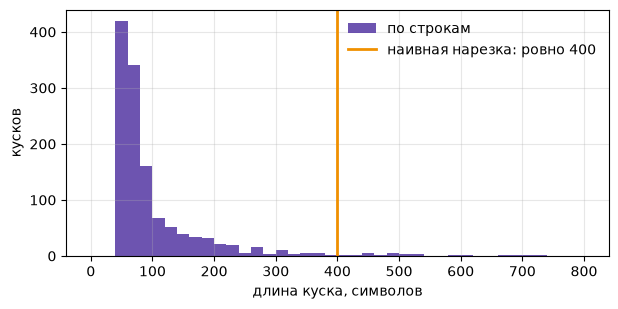

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist([len(c["text"]) for c in line_chunks], bins=40, range=(0, 800), color=COLORS["violet"], alpha=0.85, label="по строкам")
ax.axvline(400, color=COLORS["amber"], lw=2, label="наивная нарезка: ровно 400")
ax.set_xlabel("длина куска, символов"); ax.set_ylabel("кусков"); ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig("img/chunks.png", dpi=150, bbox_inches="tight")

## Эмбеддинги

In [5]:
EMB = {}


def load_cache():
    if Path("emb_cache.npz").exists():
        z = np.load("emb_cache.npz")
        EMB.update({str(k): v.astype(np.float32) for k, v in zip(z["keys"], z["vectors"])})
    return len(EMB)


def save_cache():
    np.savez_compressed("emb_cache.npz", keys=np.array(list(EMB)), vectors=np.stack(list(EMB.values())).astype(np.float16))


def embed_batch(texts):
    started = time.perf_counter()
    data = post_with_retry(EMBED_URL, {"model": EMBED_MODEL, "input": texts, "dimensions": DIM})
    ledger.add("embed", EMBED_MODEL, data.get("usage") or {}, time.perf_counter() - started)
    return [row["embedding"] for row in data["data"]]


def key_of(text):
    return hashlib.sha1(text.encode("utf-8")).hexdigest()


def embed_cached(texts):
    missing = list(dict.fromkeys(t for t in texts if key_of(t) not in EMB))
    for i in range(0, len(missing), 64):
        batch = missing[i:i + 64]
        for text, vector in zip(batch, embed_batch(batch)):
            EMB[key_of(text)] = np.asarray(vector, dtype=np.float32)
    vectors = np.stack([EMB[key_of(t)] for t in texts])
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)


def emb_text(chunk):
    return f"{chunk['page']}: {chunk['text']}"


load_cache()
line_vecs = embed_cached([emb_text(c) for c in line_chunks])
char_vecs = embed_cached([c["text"] for c in char_chunks])
q_vecs = embed_cached([t["question"] for t in tasks])
save_cache()
line_vecs.shape, char_vecs.shape, q_vecs.shape

((1274, 512), (494, 512), (117, 512))

## Проверка ответа

В ДЗ 2 `is_correct` знал числа словами только до twelve, поэтому «two people» против 2 и «Thirty thousand people»
против 30000 считались ошибками. Теперь числительные (русские и английские, составные, с «тысяч» и «миллион»)
переводятся в цифры с обеих сторон, «13,2» и «13.2» совпадают, «2 011» читается как 2011. Русские эталоны,
как в ДЗ 1, сравниваются по основам слов: «Франции» засчитывает эталон «Франция». Служебные слова эталона вроде
«около», «человек», «лет», «people» не обязательны; числа и латиница сравниваются только целиком. Ниже тесты на эти случаи, без модели.

In [6]:
EN_NUM = {w: n for n, w in enumerate("zero one two three four five six seven eight nine ten eleven twelve thirteen fourteen "
                                      "fifteen sixteen seventeen eighteen nineteen".split())}
EN_NUM |= {w: 10 * n for n, w in enumerate("twenty thirty forty fifty sixty seventy eighty ninety".split(), 2)}
RU_NUM = {}
for n, forms in enumerate(["ноль нуля", "один одна одно одного одной одному", "два две двух двум", "три трех трем", "четыре четырех четырем",
                           "пять пяти", "шесть шести", "семь семи", "восемь восьми", "девять девяти", "десять десяти",
                           "одиннадцать одиннадцати", "двенадцать двенадцати", "тринадцать тринадцати", "четырнадцать четырнадцати",
                           "пятнадцать пятнадцати", "шестнадцать шестнадцати", "семнадцать семнадцати", "восемнадцать восемнадцати",
                           "девятнадцать девятнадцати"]):
    RU_NUM |= {f: n for f in forms.split()}
for n, forms in zip(range(20, 100, 10), ["двадцать двадцати", "тридцать тридцати", "сорок сорока", "пятьдесят пятидесяти",
                                          "шестьдесят шестидесяти", "семьдесят семидесяти", "восемьдесят восьмидесяти", "девяносто девяноста"]):
    RU_NUM |= {f: n for f in forms.split()}
RU_NUM |= {"сто": 100, "ста": 100, "двести": 200, "триста": 300, "четыреста": 400, "пятьсот": 500}
MULT = {"hundred": 100, "thousand": 1000, "million": 10 ** 6, "тысяча": 1000, "тысячи": 1000, "тысяч": 1000,
        "миллион": 10 ** 6, "миллиона": 10 ** 6, "миллионов": 10 ** 6}
NUM = EN_NUM | RU_NUM
SOFT = {"около", "более", "менее", "не", "человек", "лет", "год", "года", "году", "назад", "раз", "раза", "до", "с", "по", "в",
        "people", "persons", "about", "over", "more", "than", "of"}


def numbers_to_digits(words):
    out, cur, total, inside = [], 0, 0, False
    for w in words + [""]:
        if w in NUM:
            cur, inside = cur + NUM[w], True
        elif w in MULT and inside:
            if MULT[w] == 100:
                cur = (cur or 1) * 100
            else:
                total, cur = total + (cur or 1) * MULT[w], 0
        else:
            if inside:
                out.append(str(total + cur))
                cur, total, inside = 0, 0, False
            if w in MULT and out and re.fullmatch(r"\d+", out[-1]):
                out[-1] = str(int(out[-1]) * MULT[w])   # «30 тысяч» -> 30000
            elif w:
                out.append(w)
    return out


def norm(text):
    text = str(text).lower().replace("ё", "е")
    text = re.sub(r"(?<=\d)[\s\u00a0\u202f,](?=\d{3}\b)", "", text)  # 2 011 и 30,000 -> 2011 и 30000
    text = re.sub(r"(?<=\d),(?=\d)", ".", text)                          # 13,2 -> 13.2
    text = re.sub(r"(?<!\d)\.|\.(?!\d)|[^\w\s.]", " ", text)
    words = [w for w in text.split() if w not in ("a", "an", "the")]
    return " ".join(numbers_to_digits(words))


def stem(word):
    return word[:-2] if re.fullmatch(r"[а-я]{5,}", word) else word


def word_match(gold_word, words):
    if re.fullmatch(r"[а-я]+", gold_word):
        return any(w.startswith(stem(gold_word)) for w in words)
    return gold_word in words   # числа и латиница: только целиком, иначе «13» нашлось бы в «132»


def final_answer(text):
    m = re.findall(r"FINAL:\s*(.+)", text or "")
    return m[-1].strip() if m else (text or "").strip()


def contains_answer(gold, text):
    gold, got = norm(gold), norm(text)
    if f" {gold} " in f" {got} ":
        return True
    need = [g for g in gold.split() if g not in SOFT] or gold.split()
    return all(word_match(g, got.split()) for g in need)


def is_correct(task, answer):
    got = final_answer(answer)
    return bool(got) and "NOT_FOUND" not in got and contains_answer(task["answer"], got)


def is_gold(chunk, task):
    # тот же учёт падежей, что в is_correct: эталон «Специальный суд по Косову», в цитате «Специальным судом по Косову»
    if chunk["page"] != task["page"]:
        return False
    text, words = norm(chunk["text"]), norm(task["evidence"]).split()
    return contains_answer(task["answer"], chunk["text"]) and sum(w in text for w in words) >= 0.5 * len(words)


check = lambda gold, answer: is_correct({"answer": gold}, f"FINAL: {answer}")
assert check("two people", "2") and check("two people", "2 people") and check("Thirty thousand people", "30000 people") and check("Thirty thousand", "30,000")
assert check("43", "43") and not check("43", "46") and not check("13", "132")
assert check("13,2 %", "13.2%") and check("2 011", "2011") and check("двух", "2") and check("76", "семьдесят шесть")
assert check("Франция", "сборная Франции") and check("Специальный суд по Косову", "Специальным судом по Косову")
assert check("47 человек", "47") and check("около 53 %", "53%") and not check("Больница Питт", "NOT_FOUND")
assert check("30 тысяч", "30000") and check("сто двадцать пять", "125")
"тесты проверки пройдены"

'тесты проверки пройдены'

## Recall@k по двум нарезкам

,по строкам,по 400 символов,"по строкам, свои 20","по 400 символов, свои 20"
1,0.73,0.44,0.30,0.20
3,0.85,0.57,0.50,0.35
5,0.88,0.65,0.55,0.40
10,0.91,0.74,0.70,0.50
20,0.93,0.84,0.75,0.65


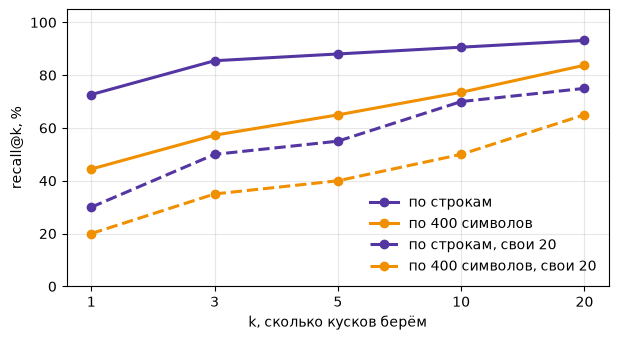

In [7]:
def search_numpy(query_vec, vectors, k=5):
    sims = vectors @ query_vec
    top = np.argsort(-sims)[:k]
    return [(int(i), float(sims[i])) for i in top]


def recall_curve(chunks, vectors, ks=(1, 3, 5, 10, 20), subset=None):
    idx = range(len(tasks)) if subset is None else subset
    ranked = {j: [i for i, _ in search_numpy(q_vecs[j], vectors, max(ks))] for j in idx}
    return {k: float(np.mean([any(is_gold(chunks[i], tasks[j]) for i in ranked[j][:k]) for j in idx])) for k in ks}


own_idx = [j for j, t in enumerate(tasks) if t["source"] == "own"]
curves = {"по строкам": recall_curve(line_chunks, line_vecs), "по 400 символов": recall_curve(char_chunks, char_vecs),
          "по строкам, свои 20": recall_curve(line_chunks, line_vecs, subset=own_idx),
          "по 400 символов, свои 20": recall_curve(char_chunks, char_vecs, subset=own_idx)}
fig, ax = plt.subplots(figsize=(7, 3.6))
for (name, curve), color, ls in zip(curves.items(), [COLORS["violet"], COLORS["amber"]] * 2, ["-", "-", "--", "--"]):
    ax.plot([str(k) for k in curve], [v * 100 for v in curve.values()], marker="o", lw=2.2, ls=ls, color=color, label=name)
ax.set_xlabel("k, сколько кусков берём"); ax.set_ylabel("recall@k, %"); ax.set_ylim(0, 105); ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig("img/recall.png", dpi=150, bbox_inches="tight")
pd.DataFrame(curves).round(2)

## Milvus

In [8]:
MILVUS_URI = os.getenv("HW4_MILVUS_URI", "http://localhost:19530")
client = MilvusClient(uri=MILVUS_URI, token=os.getenv("MILVUS_TOKEN", ""))
client.get_server_version(), client.list_collections()

('milvus_lite-3.2.2', [])

In [9]:
def index_to_milvus(name, chunks, vectors):
    if client.has_collection(name):
        client.drop_collection(name)
    client.create_collection(name, dimension=vectors.shape[1], metric_type="COSINE")
    rows = [{"id": i, "vector": v.tolist(), **c} for i, (c, v) in enumerate(zip(chunks, vectors))]
    for i in range(0, len(rows), 1000):
        client.insert(name, rows[i:i + 1000])
    client.flush(name)
    return client.get_collection_stats(name)


def search_milvus(name, query, k=5, flt=""):
    vector = embed_cached([query])[0].tolist()
    hits = client.search(name, data=[vector], limit=k, filter=flt, output_fields=["page", "section", "url", "text"])[0]
    return [{**h["entity"], "id": h["id"], "score": round(h["distance"], 4)} for h in hits]


index_to_milvus("lines", line_chunks, line_vecs)

{'row_count': 1274}

In [10]:
from_numpy = [[i for i, _ in search_numpy(q, line_vecs, 5)] for q in q_vecs]
from_milvus = [[h["id"] for h in hits] for hits in client.search("lines", data=q_vecs.tolist(), limit=5)]
overlap = float(np.mean([len(set(a) & set(b)) / 5 for a, b in zip(from_numpy, from_milvus)]))
print("совпадение топ-5 numpy и Milvus:", round(overlap, 3))
pd.DataFrame(search_milvus("lines", "лучший сценарий", 5, 'page == "83-й Венецианский кинофестиваль"'))[["score", "page", "section", "text"]]

совпадение топ-5 numpy и Milvus: 1.0


,score,page,section,text
0,0.4369,83-й Венецианский кинофестиваль,Официальные награды,Приз за лучший сценарий — Томмазо Ландуччи и Д...
1,0.4319,83-й Венецианский кинофестиваль,Официальные награды,"Приз за лучший сценарий — Корали Амедео, Стефа..."
2,0.3673,83-й Венецианский кинофестиваль,Независимые награды,Лучший фильм программы «Горизонты» и параллель...
3,0.3566,83-й Венецианский кинофестиваль,Официальные награды,"Приз за лучший фильм — «Поворот через Диану», ..."
4,0.3482,83-й Венецианский кинофестиваль,Официальные награды,Приз Луиджи Де Лаурентиса — Лев будущего за лу...


## Скорость и масштаб

,"numpy, перебор","Milvus, запрос на вызов","Milvus, пачкой"
векторов,,,
1274,0.37,8.86,1.72
50000,12.39,150.88,3.34
200000,62.38,274.70,7.17


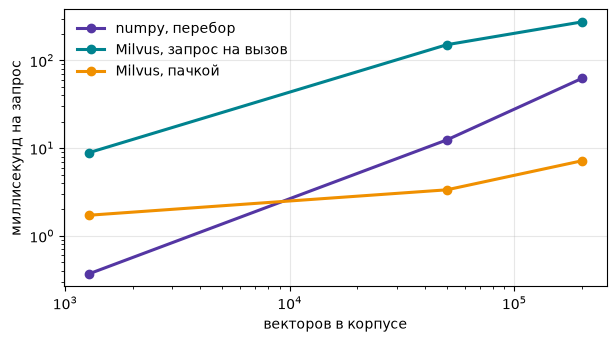

In [11]:
def per_query_ms(fn, n=100):
    started = time.perf_counter()
    fn()
    return (time.perf_counter() - started) * 1000 / n


def inflate(vectors, n, noise=0.35, seed=0):
    rng = np.random.default_rng(seed)
    extra = vectors[rng.integers(0, len(vectors), n - len(vectors))]
    extra = extra + noise * rng.standard_normal(extra.shape, dtype=np.float32) / np.sqrt(vectors.shape[1])
    return np.vstack([vectors, extra / np.linalg.norm(extra, axis=1, keepdims=True)])


def wait_index(name, seconds=180):
    for _ in range(seconds):
        info = client.describe_index(name, "vector")
        if info.get("state") == "Finished" and info.get("pending_index_rows", 0) == 0:
            return True
        time.sleep(1)
    return False


scale_rows, probe = [], q_vecs[:50]
for n in (len(line_vecs), 50_000, 200_000):
    big = inflate(line_vecs, n) if n > len(line_vecs) else line_vecs
    if client.has_collection("scale"):
        client.drop_collection("scale")
    client.create_collection("scale", dimension=big.shape[1], metric_type="COSINE")
    for i in range(0, n, 5000):
        client.insert("scale", [{"id": i + j, "vector": v} for j, v in enumerate(big[i:i + 5000].tolist())])
    client.flush("scale")
    wait_index("scale")
    client.search("scale", data=[q_vecs[0].tolist()], limit=5)
    scale_rows.append({"векторов": n,
                       "numpy, перебор": per_query_ms(lambda: [search_numpy(q, big, 5) for q in probe], 50),
                       "Milvus, запрос на вызов": per_query_ms(lambda: [client.search("scale", data=[q.tolist()], limit=5) for q in probe], 50),
                       "Milvus, пачкой": per_query_ms(lambda: client.search("scale", data=probe.tolist(), limit=5), 50)})
client.drop_collection("scale")
scale = pd.DataFrame(scale_rows).set_index("векторов")
ax = scale.plot(figsize=(7, 3.6), marker="o", lw=2.2, logx=True, logy=True, color=[COLORS["violet"], COLORS["teal"], COLORS["amber"]])
ax.set_ylabel("миллисекунд на запрос"); ax.set_xlabel("векторов в корпусе"); ax.legend(frameon=False); ax.grid(alpha=0.3)
ax.figure.savefig("img/scale.png", dpi=150, bbox_inches="tight")
scale.round(2)

## Гибрид: вектор, слова, RRF

Поиск по словам в русском тексте спотыкается о падежи: «Франции» и «Франция» — разные слова. Поэтому меряю
два варианта словарного поиска: по словам как есть и по основам (то же `stem`, что в проверке ответа).

,нарезка,поиск,recall@1,recall@5,recall@10
0,по 400 символов,только вектор,0.44,0.65,0.74
1,по 400 символов,слова как есть,0.70,0.85,0.89
2,по 400 символов,слова по основам,0.73,0.85,0.91
3,по 400 символов,гибрид RRF (вектор + основы),0.52,0.77,0.88
4,по строкам,только вектор,0.73,0.88,0.91
5,по строкам,слова как есть,0.82,0.95,0.95
6,по строкам,слова по основам,0.83,0.97,0.97
7,по строкам,гибрид RRF (вектор + основы),0.79,0.95,0.98


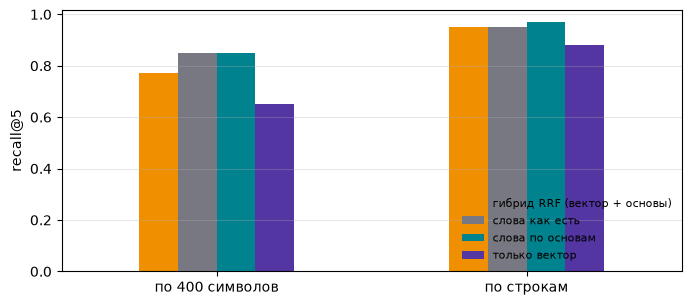

In [12]:
def tokens(text, stems=True):
    words = re.findall(r"\w+", text.lower().replace("ё", "е"))
    return [stem(w) for w in words] if stems else words


def build_keyword_index(texts, stems=True):
    docs = [set(tokens(text, stems)) for text in texts]
    df = {}
    for d in docs:
        for w in d:
            df[w] = df.get(w, 0) + 1
    return docs, {w: np.log(len(docs) / n) for w, n in df.items()}


def keyword_search(query, docs, idf, k=20, stems=True):
    q = set(tokens(query, stems))
    scores = np.array([sum(idf.get(w, 0.0) for w in q & d) for d in docs])
    return [int(i) for i in np.argsort(-scores)[:k]]


def rrf(rankings, k=5, K=60):
    scores = {}
    for ranking in rankings:
        for rank, idx in enumerate(ranking):
            scores[idx] = scores.get(idx, 0.0) + 1 / (K + rank + 1)
    return sorted(scores, key=scores.get, reverse=True)[:k]


def recall_of(rankings, chunks, k=5):
    return float(np.mean([any(is_gold(chunks[i], t) for i in r[:k]) for r, t in zip(rankings, tasks)]))


rows = []
for cut, chunks, vectors, texts in [("по 400 символов", char_chunks, char_vecs, [c["text"] for c in char_chunks]),
                                    ("по строкам", line_chunks, line_vecs, [emb_text(c) for c in line_chunks])]:
    raw_docs, raw_idf = build_keyword_index(texts, stems=False)
    docs, idf = build_keyword_index(texts)
    by_vector = [[i for i, _ in search_numpy(q, vectors, 20)] for q in q_vecs]
    by_raw = [keyword_search(t["question"], raw_docs, raw_idf, 20, stems=False) for t in tasks]
    by_words = [keyword_search(t["question"], docs, idf, 20) for t in tasks]
    by_hybrid = [rrf([v, w], 20) for v, w in zip(by_vector, by_words)]
    rows += [{"нарезка": cut, "поиск": name, "recall@1": recall_of(r, chunks, 1), "recall@5": recall_of(r, chunks, 5),
              "recall@10": recall_of(r, chunks, 10)}
             for name, r in [("только вектор", by_vector), ("слова как есть", by_raw), ("слова по основам", by_words),
                             ("гибрид RRF (вектор + основы)", by_hybrid)]]
hybrid = pd.DataFrame(rows).round(2)
ax = hybrid.pivot(index="нарезка", columns="поиск", values="recall@5").plot.bar(figsize=(8, 3.4), rot=0,
    color=[COLORS["amber"], COLORS["grey"], COLORS["teal"], COLORS["violet"]])
ax.set_ylabel("recall@5"); ax.set_xlabel(""); ax.legend(frameon=False, loc="lower right", fontsize=8); ax.grid(alpha=0.3, axis="y")
ax.figure.savefig("img/hybrid.png", dpi=150, bbox_inches="tight")
hybrid

## RAG-ответ, инструменты агента и замер

In [13]:
RAG_SYSTEM = ("Answer the question using only the numbered sources. Cite the source number like [2]. Answer in the language of the question. "
              "If the sources do not contain the answer, reply exactly NOT_FOUND. The last line must be FINAL: <short answer>.")
PLAIN_SYSTEM = ("Answer the question. Answer in the language of the question. If you do not know, reply NOT_FOUND. "
                "The last line must be FINAL: <short answer>.")


def rag_answer(question, model, k=5, name="lines"):
    hits = search_milvus(name, question, k)
    sources = "\n".join(f"[{i + 1}] ({h['page']}) {h['text']}" for i, h in enumerate(hits))
    before = ledger.mine
    msg = chat([{"role": "system", "content": RAG_SYSTEM},
                {"role": "user", "content": f"Sources\n{sources}\n\nQuestion: {question}"}], model, tag="rag")
    return {"answer": msg.get("content") or "", "hits": hits, "cost": ledger.mine - before}


def plain_answer(question, model):
    before = ledger.mine
    msg = chat([{"role": "system", "content": PLAIN_SYSTEM}, {"role": "user", "content": question}], model, tag="plain")
    return {"answer": msg.get("content") or "", "hits": [], "cost": ledger.mine - before}


def evaluate(fn, sample, config, model, workers=8):
    def one(task):
        try:
            out = fn(task["question"], model)
        except Exception as e:
            out = {"answer": f"ошибка: {e}", "hits": [], "cost": 0.0}
        return {"config": config, "model": model.split("/")[-1], "id": task["id"], "source": task["source"],
                "correct": is_correct(task, out["answer"]), "found": any(is_gold(h, task) for h in out["hits"]),
                "refused": "NOT_FOUND" in out["answer"], "cost": out["cost"], "answer": final_answer(out["answer"])[:80],
                "gold": task["answer"], "raw": out["answer"]}
    with ThreadPoolExecutor(workers) as pool:
        return pd.DataFrame(list(pool.map(one, sample)))


def report(results):
    g = results.groupby(["config", "model"], sort=False)
    table = g.agg(n=("correct", "size"), accuracy=("correct", "mean"), cost_per_task=("cost", "mean")).reset_index()
    table["cost_per_correct"] = table["cost_per_task"] / table["accuracy"].replace(0, float("nan"))
    return table.round(5)


def money_chart(table, path, baseline=None):
    fig, ax = plt.subplots(figsize=(8, 4.6))
    if baseline:
        ax.axhline(baseline[1] * 100, color=COLORS["grey"], ls="--", lw=1.2)
        ax.annotate(baseline[0], (0.01, baseline[1] * 100 + 1.5), xycoords=("axes fraction", "data"), fontsize=8, color=COLORS["grey"])
    for _, r in table.iterrows():
        color = COLORS["amber"] if "sonnet" in r["model"] else COLORS["teal"] if "haiku" in r["model"] else COLORS["violet"]
        ax.scatter(r["cost_per_task"] * 100, r["accuracy"] * 100, s=110, color=color)
        ax.annotate(f"{r['config']}\n{r['model']}", (r["cost_per_task"] * 100, r["accuracy"] * 100), fontsize=8, xytext=(7, 3), textcoords="offset points")
    ax.set_xscale("log"); ax.set_xlabel("цена вопроса, центы (логарифмическая шкала)"); ax.set_ylabel("доля верных, %"); ax.set_ylim(-3, 105)
    ax.grid(alpha=0.3)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return fig


out = rag_answer(tasks[0]["question"], MODELS["cheap"])
print(out["answer"], "| эталон:", tasks[0]["answer"], "| цена, центов:", round(out["cost"] * 100, 4))

NOT_FOUND.  
FINAL: NOT_FOUND. | эталон: Больница Питт | цена, центов: 0.0052


In [14]:
TOOLS = {}


def register(fn, args_model, description):
    TOOLS[fn.__name__] = {"fn": fn, "args": args_model, "schema": {"type": "function", "function": {
        "name": fn.__name__, "description": description, "parameters": args_model.model_json_schema()}}}


def run_tool(call):
    name = call["function"]["name"]
    try:
        spec = TOOLS[name]
        result = spec["fn"](**spec["args"].model_validate_json(call["function"]["arguments"]).model_dump())
    except Exception as e:
        result = f"ошибка инструмента {name}: {e}"
    return {"role": "tool", "tool_call_id": call["id"], "content": str(result)[:3000]}


AGENT_SYSTEM = ("You answer questions about events of 2026. Never answer from memory: look facts up with the tools, do not repeat the same call. "
                "Answer in the language of the question. "
                "When done, write the last line as FINAL: <short answer>, or NOT_FOUND if the tools give no answer.")


def agent(question, model, max_steps=6, names=None, tag="agent"):
    pool = TOOLS if names is None else {n: TOOLS[n] for n in names}
    messages, seen, before, calls = [{"role": "system", "content": AGENT_SYSTEM}, {"role": "user", "content": question}], set(), ledger.mine, []
    schemas = [t["schema"] for t in pool.values()]
    for step in range(max_steps):
        msg = chat(messages, model, tools=schemas, tag=tag)
        messages.append(msg)
        calls = msg.get("tool_calls") or []
        keys = {(c["function"]["name"], c["function"]["arguments"]) for c in calls}
        if not calls or keys & seen or step == max_steps - 1:
            break
        seen |= keys
        messages += [run_tool(c) for c in calls]
    if calls:
        messages += [{"role": "tool", "tool_call_id": c["id"], "content": "call rejected: answer from what you already have"} for c in calls]
        msg = chat(messages, model, tag=tag)
    searches = sum(m.get("role") == "tool" for m in messages if isinstance(m, dict))
    return {"answer": msg.get("content") or "", "hits": [], "cost": ledger.mine - before, "searches": searches}

### Инструмент `knowledge_base` и его тест на три случая (без модели)

In [15]:
class KBArgs(BaseModel):
    query: str = Field(description="short search query in Russian: names, dates, key terms of the event")
    page: str = Field(default="", description="optional exact page title to search within, for example '83-й Венецианский кинофестиваль'; empty means all pages")


PAGES = {c["page"] for c in corpus}


def knowledge_base(query: str, page: str = "") -> str:
    if page and page not in PAGES:
        return f"no such page: {page}. Leave page empty to search everywhere"
    hits = search_milvus("lines", query, 5, f'page == "{page}"' if page else "")
    if not hits:
        return "nothing found"
    return "\n".join(f"[{h['page']} / {h['section']}] {h['text']}" for h in hits)


register(knowledge_base, KBArgs, "Searches the local knowledge base (Russian Wikipedia, 2026 events) and returns the five closest facts with their page and section")

# 1) факт находится: строка-эталон своего вопроса в выдаче
found = knowledge_base("новый вид кошачьих Боливия")
assert "Leopardus tilcayo" in found, found
# 2) фильтр по странице: все пять кусков с нужной страницы, чужих нет
venice = knowledge_base("лучший сценарий", page="83-й Венецианский кинофестиваль")
assert all(line.startswith("[83-й Венецианский кинофестиваль /") for line in venice.splitlines()), venice
# 3) несуществующая страница: понятный отказ вместо пустого фильтра Milvus
assert knowledge_base("лучший сценарий", page="84-й Венецианский кинофестиваль").startswith("no such page")
"тесты knowledge_base пройдены"

'тесты knowledge_base пройдены'

### Живой поиск из ДЗ 1 (web_search и page_find с lang)

In [16]:
# Википедия режет частые запросы (429 с Retry-After), строже всего без контакта в User-Agent.
# Ответы кэшируются на диск: повторный прогон не ходит в сеть за тем же, а ошибки инструмента считаются отдельно,
# чтобы строка «живой поиск» не проигрывала из-за лимитов вместо поиска.
WIKI_HEADERS = {"User-Agent": "agents-course-hw4/1.0 (https://github.com/shilnikovAD/workchat-agent; educational project)"}
WIKI_CACHE_FILE = Path("wiki_cache.json")
WIKI_CACHE = json.loads(WIKI_CACHE_FILE.read_text(encoding="utf-8")) if WIKI_CACHE_FILE.exists() else {}
WIKI_ERRORS = []
wiki_lock = threading.Lock()


def wiki(params, lang, attempts=6):
    key = json.dumps({**params, "lang": lang}, sort_keys=True, ensure_ascii=False)
    if key in WIKI_CACHE:
        return WIKI_CACHE[key]
    url = f"https://{lang}.wikipedia.org/w/api.php"
    for attempt in range(attempts):
        try:
            r = requests.get(url, params={**params, "format": "json"}, headers=WIKI_HEADERS, timeout=20)
            if r.status_code == 200 and r.headers.get("content-type", "").startswith("application/json"):
                with wiki_lock:
                    WIKI_CACHE[key] = r.json().get("query", {})
                return WIKI_CACHE[key]
            wait = max(3.0 * (attempt + 1), float(r.headers.get("Retry-After", 0) or 0))
        except requests.RequestException:
            wait = 3.0 * (attempt + 1)
        time.sleep(min(wait, 90))
    WIKI_ERRORS.append(params)
    raise RuntimeError("Википедия не ответила")


def save_wiki_cache():
    with wiki_lock:
        WIKI_CACHE_FILE.write_text(json.dumps(WIKI_CACHE, ensure_ascii=False), encoding="utf-8")


class SearchArgs(BaseModel):
    query: str = Field(description="короткий поисковый запрос: имя, название, термин")
    lang: Literal["en", "ru"] = Field(default="en", description="en для международных тем, ru для событий в России и СНГ и для вопросов на русском")


class PageFindArgs(BaseModel):
    title: str = Field(description="точное название статьи, например '2026 in France'")
    keywords: str = Field(description="2-4 ключевых слова из вопроса через пробел: имена, числа, термины")
    lang: Literal["en", "ru"] = Field(default="en", description="язык Википедии, как в web_search")


def web_search(query, lang="en"):
    hits = wiki({"action": "query", "list": "search", "srsearch": query, "srlimit": 1}, lang).get("search", [])
    if not hits:
        return "No data"
    pages = wiki({"action": "query", "prop": "extracts", "explaintext": 1, "exintro": 1, "titles": hits[0]["title"]}, lang)["pages"]
    text = " ".join(next(iter(pages.values())).get("extract", "").split())
    return f"[{hits[0]['title']}] {text[:2000]}"


def page_find(title, keywords, lang="en"):
    pages = wiki({"action": "query", "prop": "extracts", "explaintext": 1, "titles": title, "redirects": 1}, lang)["pages"]
    text = next(iter(pages.values())).get("extract", "")
    if not text:
        return "no such page"
    words = [w for w in re.findall(r"\w+", keywords.lower()) if len(w) > 2]
    lines = [l.strip() for l in text.splitlines() if l.strip()]
    scored = [(sum(w in l.lower() for w in words), l) for l in lines]
    hits = [l for n, l in sorted(scored, key=lambda x: -x[0]) if n > 0][:6]
    return "\n".join(h[:400] for h in hits) or "keywords not found on the page"


register(web_search, SearchArgs, "Ищет статью в Википедии и возвращает её вступление")
register(page_find, PageFindArgs, "Читает полный текст статьи Википедии и возвращает строки с ключевыми словами")


def agent_kb(question, model, max_steps=6):
    return agent(question, model, max_steps, names=["knowledge_base"])


def agent_live_search(question, model, max_steps=6):
    return agent(question, model, max_steps, names=["web_search", "page_find"], tag="agent_live")


out = agent_kb(tasks[3]["question"], MODELS["cheap"])
print(out["answer"], "| эталон:", tasks[3]["answer"], "| обращений к базе:", out["searches"])

Хашим Тачи был приговорён к 25 годам лишения свободы. 

FINAL: 25 | эталон: 25 | обращений к базе: 1


### Выбор k: свип на всех вопросах

,config,model,n,accuracy,cost_per_task,cost_per_correct
0,k=1,gpt-4o-mini,117,0.73504,0.00004,0.00006
1,k=3,gpt-4o-mini,117,0.76923,0.00006,0.00008
2,k=5,gpt-4o-mini,117,0.76923,0.00008,0.00010
3,k=10,gpt-4o-mini,117,0.75214,0.00012,0.00016


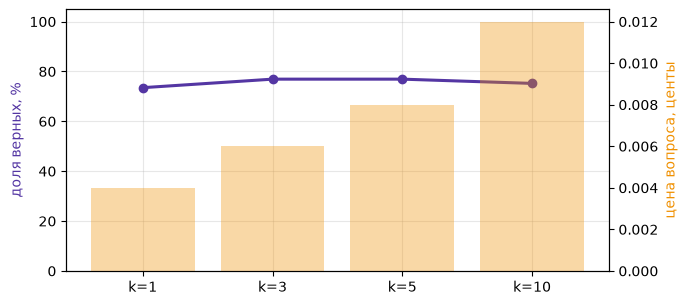

In [17]:
sweep = pd.concat([evaluate(lambda q, m, k=k: rag_answer(q, m, k), tasks, f"k={k}", MODELS["cheap"]) for k in (1, 3, 5, 10)], ignore_index=True)
sweep_table = report(sweep)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(sweep_table["config"], sweep_table["accuracy"] * 100, marker="o", lw=2.2, color=COLORS["violet"]); ax.set_ylabel("доля верных, %", color=COLORS["violet"])
ax2 = ax.twinx(); ax2.bar(sweep_table["config"], sweep_table["cost_per_task"] * 100, alpha=0.35, color=COLORS["amber"]); ax2.set_ylabel("цена вопроса, центы", color=COLORS["amber"])
ax.set_ylim(0, 105); ax.grid(alpha=0.3)
fig.savefig("img/k_sweep.png", dpi=150, bbox_inches="tight")
sweep_table

### Пять обязательных строк на всех вопросах

In [18]:
full_results = pd.concat([
    evaluate(plain_answer, tasks, "сильная модель, без инструментов", MODELS["strong"]),
    evaluate(agent_live_search, tasks, "дешёвая модель, живой поиск ДЗ 1", MODELS["cheap"], workers=1),
    evaluate(rag_answer, tasks, "дешёвая модель, RAG всегда", MODELS["cheap"]),
    evaluate(agent_kb, tasks, "дешёвая модель, агент + knowledge_base", MODELS["cheap"]),
    evaluate(rag_answer, tasks, "средняя модель, RAG всегда", MODELS["mid"]),
], ignore_index=True)
save_wiki_cache()
print("запросов к Википедии без ответа после всех попыток:", len(WIKI_ERRORS))
full_results.drop(columns=["raw"]).to_csv("results/answers_full.csv", index=False)
full_table = report(full_results)
full_table

запросов к Википедии без ответа после всех попыток: 0


,config,model,n,accuracy,cost_per_task,cost_per_correct
0,"сильная модель, без инструментов",claude-sonnet-4.6,117,0.06838,0.00239,0.03501
1,"дешёвая модель, живой поиск ДЗ 1",gpt-4o-mini,117,0.37607,0.00060,0.00161
2,"дешёвая модель, RAG всегда",gpt-4o-mini,117,0.76068,0.00008,0.00011
3,"дешёвая модель, агент + knowledge_base",gpt-4o-mini,117,0.82906,0.00026,0.00031
4,"средняя модель, RAG всегда",claude-haiku-4.5,117,0.81197,0.00100,0.00123


In [19]:
# те же конфигурации отдельно на своих 20 вопросах и на вопросах по корпусу
by_source = full_results.groupby(["config", "source"], sort=False)["correct"].mean().unstack().round(3)
hw1_own = float(np.mean([t["agent_ok"] for t in own]))
print(f"ДЗ 1, агент с живым поиском на своих 20 вопросах (поле agent_ok): {hw1_own:.3f}")
by_source

ДЗ 1, агент с живым поиском на своих 20 вопросах (поле agent_ok): 0.000


source,own,generated
config,,
"сильная модель, без инструментов",0.00,0.082
"дешёвая модель, живой поиск ДЗ 1",0.75,0.299
"дешёвая модель, RAG всегда",0.45,0.825
"дешёвая модель, агент + knowledge_base",0.60,0.876
"средняя модель, RAG всегда",0.55,0.866


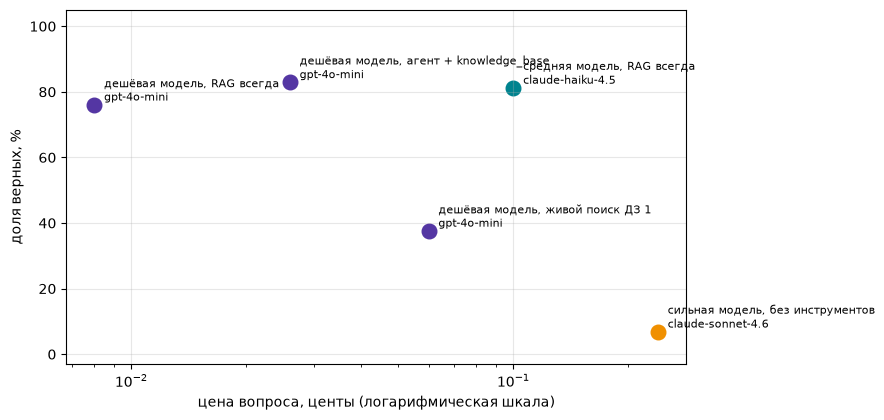

In [20]:
money_chart(full_table, "img/money_full.png");

### Разбор ошибок RAG: поиск или генерация

In [21]:
rag_rows = full_results[full_results["config"].str.contains("RAG")]
wrong = rag_rows[~rag_rows["correct"]]
print(wrong.groupby("model").agg(не_нашли=("found", lambda s: int((~s).sum())), нашли_но_ответ_неверный=("found", "sum")))
questions = {t["id"]: t["question"] for t in tasks}
pd.set_option("display.max_colwidth", 120)
cheap_wrong = wrong[wrong["model"] == "gpt-4o-mini"].assign(question=lambda d: d["id"].map(questions))
cheap_wrong[["id", "question", "gold", "answer", "found"]]

                  не_нашли  нашли_но_ответ_неверный
model                                              
claude-haiku-4.5        13                        9
gpt-4o-mini             13                       15


,id,question,gold,answer,found
234,fresh-125,Какой сериал был признан лучшим драматическим сериалом на 78-й церемонии вручения премии «Эмми» в 2026 году?,Больница Питт,NOT_FOUND.,True
235,fresh-126,Какой сериал получил награду как лучший комедийный сериал на 78-й церемонии премии «Эмми» в 2026 году?,Бухта вдов,NOT_FOUND,False
236,fresh-127,Какой проект был признан лучшим мини-сериалом на 78-й церемонии премии «Эмми» в 2026 году?,ГКС. Сент-Луис,NOT_FOUND,True
238,fresh-129,Каким судом был приговорён бывший президент Косово Хашим Тачи в сентябре 2026 года?,Специальный суд по Косову,Судебной коллегией Специализированных палат по Косову в Гааге.,True
242,fresh-133,Сборная какой страны выиграла чемпионат мира по баскетболу среди женщин 2026 года?,США,NOT_FOUND.,False
243,fresh-134,Сборную какой страны обыграли в финале чемпионата мира по баскетболу среди женщин 2026 года?,Франция,NOT_FOUND,False
244,fresh-135,Кто выиграл мужской одиночный разряд Открытого чемпионата США по теннису 2026 года?,Александр Зверев,NOT_FOUND.,False
245,fresh-136,Кто выиграл женский одиночный разряд Открытого чемпионата США по теннису 2026 года?,Елена Рыбакина,NOT_FOUND.,False
246,fresh-137,Кем стала Елена Рыбакина в мировом рейтинге после победы на Открытом чемпионате США 2026 года?,первая ракетка мира,NOT_FOUND.,False
249,fresh-140,Какой фильм получил «Золотого льва» на 83-м Венецианском кинофестивале в 2026 году?,Неизвестная женщина,NOT_FOUND.,False


## Отказы на своих десяти вопросах без ответа

In [22]:
def refused(answer):
    return "NOT_FOUND" in answer or "nothing found" in answer.lower()


refusal_rows = []
for name, fn in [("RAG всегда", rag_answer), ("агент + knowledge_base", agent_kb)]:
    out = evaluate(fn, unanswerable, name, MODELS["cheap"])
    answerable = full_results[full_results["config"] == ("дешёвая модель, RAG всегда" if fn is rag_answer else "дешёвая модель, агент + knowledge_base")]
    refusal_rows.append({"конфигурация": name, "честно отклонено из 10 безответных": int(out["raw"].map(refused).sum()),
                         f"зря отклонено из {len(answerable)} отвечаемых": int(answerable["raw"].map(refused).sum()),
                         "выдумки на безответных": "; ".join(out.loc[~out["raw"].map(refused), "answer"].str[:50])})
refusal_table = pd.DataFrame(refusal_rows)
refusal_table

,конфигурация,честно отклонено из 10 безответных,зря отклонено из 117 отвечаемых,выдумки на безответных
0,RAG всегда,10,21,
1,агент + knowledge_base,9,7,23 минуты 50 секунд


(0.744, 0.633)

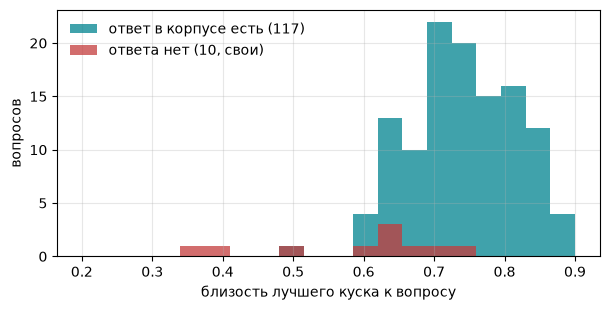

In [23]:
un_vecs = embed_cached([t["question"] for t in unanswerable])
top_answerable = [search_numpy(q, line_vecs, 1)[0][1] for q in q_vecs]
top_unanswerable = [search_numpy(q, line_vecs, 1)[0][1] for q in un_vecs]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(top_answerable, bins=20, range=(0.2, 0.9), alpha=0.75, color=COLORS["teal"], label=f"ответ в корпусе есть ({len(tasks)})")
ax.hist(top_unanswerable, bins=20, range=(0.2, 0.9), alpha=0.75, color=COLORS["red"], label=f"ответа нет ({len(unanswerable)}, свои)")
ax.set_xlabel("близость лучшего куска к вопросу"); ax.set_ylabel("вопросов"); ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig("img/refusal_scores.png", dpi=150, bbox_inches="tight")
round(float(np.median(top_answerable)), 3), round(float(np.median(top_unanswerable)), 3)

## Долгая память: свой диалог

Пользователь Артём, кинокритик из Казани, следит за кино и теннисом. Во второй сессии теннис бросает ради баскетбола
и переезжает в Санкт-Петербург: факты должны замениться, а не задублироваться.

In [24]:
FACTS_SYSTEM = ("Ты ведёшь память ассистента о пользователе. Верни один JSON-объект вида {\"facts\": [\"...\"]}: полный обновлённый список "
                "коротких фактов о пользователе. Добавь новые устойчивые факты: имя, город, работа, интересы, пожелания к ответам. "
                "Если новый факт отменяет старый, замени старый. Разовые вопросы и мелочи не записывай.")
ASSISTANT_SYSTEM = ("Ты помощник, который отвечает на вопросы о событиях 2026 года по базе знаний. Отвечай на языке пользователя, "
                    "опирайся на источники и на то, что знаешь о пользователе. Источники подобраны автоматически и могут быть не по теме: "
                    "используй только те, что относятся к вопросу. Если в источниках ответа нет, так и скажи.")
JOURNAL, FACTS_FILE = Path("episodes.jsonl"), Path("facts.json")


class Facts(BaseModel):
    facts: list[str] = Field(description="короткие факты о пользователе")


def json_from(text):
    m = re.search(r"\{.*\}", text or "", re.S)
    return json.loads(m.group(0) if m else "{}", strict=False)


def known_facts():
    return json.loads(FACTS_FILE.read_text(encoding="utf-8")) if FACTS_FILE.exists() else []


def store_facts(facts):
    FACTS_FILE.write_text(json.dumps(facts, ensure_ascii=False, indent=1), encoding="utf-8")
    if facts:
        index_to_milvus("facts", [{"page": "memory", "section": "", "url": "", "text": f} for f in facts], embed_cached(facts))


def remember_episode(session, role, text):
    with JOURNAL.open("a", encoding="utf-8") as f:
        f.write(json.dumps({"session": session, "time": time.strftime("%Y-%m-%d %H:%M:%S"), "role": role, "text": text}, ensure_ascii=False) + "\n")


def extract_facts(dialog, known):
    prompt = f"Известные факты: {json.dumps(known, ensure_ascii=False)}\n\nДиалог:\n{dialog}"
    msg = chat([{"role": "system", "content": FACTS_SYSTEM}, {"role": "user", "content": prompt}], MODELS["cheap"], tag="memory")
    return Facts.model_validate(json_from(msg["content"])).facts


def recall_facts_from(collection, question, k=3):
    if not client.has_collection(collection):
        return []
    return [h["text"] for h in search_milvus(collection, question, k)]


def recall_facts(question, k=3):
    return recall_facts_from("facts", question, k)


def search_with_memory(user_text, facts, k=5):
    plain = search_milvus("lines", user_text, k)
    personal = search_milvus("lines", user_text + " " + " ".join(facts), k) if facts else []
    by_id = {h["id"]: h for h in plain + personal}
    return [by_id[i] for i in rrf([[h["id"] for h in plain], [h["id"] for h in personal]], k)]


def talk(session, history, user_text, mode="память"):
    remember_episode(session, "user", user_text)
    facts = recall_facts(user_text) if mode == "память" else []
    hits = search_with_memory(user_text, facts) if "?" in user_text else []
    sources = "\n".join(f"[{i + 1}] ({h['page']}) {h['text']}" for i, h in enumerate(hits)) or "нет"
    system = ASSISTANT_SYSTEM + ("\nЧто известно о пользователе: " + "; ".join(facts) if facts else "")
    window = history[-4:] if mode == "память" else history
    msg = chat([{"role": "system", "content": system}] + window + [{"role": "user", "content": f"Источники:\n{sources}\n\n{user_text}"}],
               MODELS["cheap"], tag=f"dialog: {mode}")
    answer = msg.get("content") or ""
    history += [{"role": "user", "content": user_text if mode == "память" else f"Источники:\n{sources}\n\n{user_text}"},
                {"role": "assistant", "content": answer}]
    remember_episode(session, "assistant", answer)
    return answer


def end_session(history):
    dialog = "\n".join(f"{m['role']}: {m['content'][:400]}" for m in history)
    store_facts(extract_facts(dialog, known_facts()))
    return known_facts()


for path in (JOURNAL, FACTS_FILE):
    path.unlink(missing_ok=True)
if client.has_collection("facts"):
    client.drop_collection("facts")

### Тесты памяти без модели: пустая память, найденный факт, заменённый факт

In [25]:
assert recall_facts_from("facts_test_nonexistent", "где живёт пользователь") == []

test_facts = ["Пользователь живёт в Казани", "Пользователь работает кинокритиком"]
index_to_milvus("facts_test", [{"page": "memory", "section": "", "url": "", "text": f} for f in test_facts], embed_cached(test_facts))
found = recall_facts_from("facts_test", "в каком городе живёт пользователь", k=1)
assert found and "Казан" in found[0], found

updated = ["Пользователь живёт в Санкт-Петербурге", "Пользователь работает кинокритиком"]
index_to_milvus("facts_test", [{"page": "memory", "section": "", "url": "", "text": f} for f in updated], embed_cached(updated))
now = [h["text"] for h in client.query("facts_test", filter="", output_fields=["text"], limit=100)]
assert not any("Казан" in t for t in now) and any("Петербург" in t for t in now), now
client.drop_collection("facts_test")
"тесты памяти пройдены"

'тесты памяти пройдены'

In [26]:
first = []
print(talk("s1", first, "Привет! Я Артём, кинокритик из Казани. Слежу за кино и теннисом, отвечай подробно и называй режиссёров."))
print(talk("s1", first, "Кто получил главные призы Венецианского кинофестиваля в 2026 году?"))
end_session(first)

Привет, Артём! Рад помочь тебе с вопросами о событиях 2026 года. К сожалению, у меня нет конкретных источников о кино или теннисе за этот год, так как информация о событиях 2026 года пока недоступна. Если у тебя есть какие-то конкретные вопросы или темы, которые тебя интересуют, дай знать, и я постараюсь ответить на основе имеющихся знаний!


На 83-м Венецианском международном кинофестивале, который проходил с 2 по 12 сентября 2026 года, главные призы были распределены следующим образом:

- Фильм открытия фестиваля — «Чернила» режиссёра Дэнни Бойла.
- Главный приз фестиваля, «Золотого льва», получил фильм «Неизвестная женщина» датского режиссёра Май эль-Туки.
- Жюри основного конкурса возглавила американская актриса и режиссёр Мэгги Джилленхол.

Если у тебя есть дополнительные вопросы о фестивале или других событиях, дай знать!


['Имя: Артём',
 'Город: Казань',
 'Работа: кинокритик',
 'Интересы: кино, теннис',
 'Пожелания к ответам: отвечай подробно и называй режиссёров']

In [27]:
second = []
print(talk("s2", second, "Что нового в моих темах за сентябрь?"))
print(talk("s2", second, "Теннис я бросил, теперь слежу за баскетболом. И я переехал в Санкт-Петербург."))
print(talk("s2", second, "Кто выиграл женский чемпионат мира по баскетболу 2026 года?"))
end_session(second)

К сожалению, в предоставленных источниках нет информации о событиях в кино или теннисе за сентябрь 2026 года. Однако, если вас интересует, что будет происходить в киноиндустрии в 2026 году, вы можете ожидать, что в это время пройдет 83-й Венецианский кинофестиваль, который, как правило, проходит в начале сентября. На этом фестивале будут представлены новые фильмы, и, возможно, вы сможете увидеть работы известных режиссёров.

Если у вас есть конкретные вопросы о фильмах или теннисных событиях, пожалуйста, уточните, и я постараюсь помочь!


Спасибо за обновленную информацию, Артём! К сожалению, у меня нет данных о событиях в кино или баскетболе за сентябрь 2026 года. Если вас интересуют какие-то конкретные турниры по баскетболу или фильмы, которые могут выйти в это время, дайте знать, и я постараюсь помочь!


В 2026 году чемпионат мира по баскетболу среди женщин проходил, но, к сожалению, у меня нет информации о том, какая команда выиграла этот турнир. Если вам нужна более подробная информация о результатах или командах, участвовавших в чемпионате, дайте знать, и я постараюсь помочь!


['Имя: Артём',
 'Город: Санкт-Петербург',
 'Работа: кинокритик',
 'Интересы: кино, баскетбол',
 'Пожелания к ответам: отвечай подробно и называй режиссёров']

In [28]:
current = known_facts()
print("факты после двух сессий:", current)
assert any("Петербург" in f for f in current) and not any("Казан" in f for f in current), "город должен замениться"
assert any("баскетбол" in f.lower() for f in current), "новый интерес должен появиться"

факты после двух сессий: ['Имя: Артём', 'Город: Санкт-Петербург', 'Работа: кинокритик', 'Интересы: кино, баскетбол', 'Пожелания к ответам: отвечай подробно и называй режиссёров']


,prompt,cost
tag,,
dialog: память,6462,0.00128
dialog: вся история,22351,0.00252


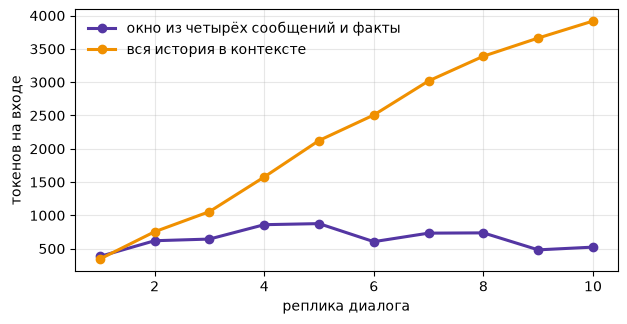

In [29]:
SCRIPT = [t["question"] for t in own[:10]]
for mode in ("память", "вся история"):
    history = []
    for q in SCRIPT:
        talk("bench", history, q, mode)
per_turn = pd.DataFrame([c for c in ledger.calls if c["tag"].startswith("dialog: ")][-2 * len(SCRIPT):])
fig, ax = plt.subplots(figsize=(7, 3.4))
for (tag, part), color in zip(per_turn.groupby("tag", sort=False), [COLORS["violet"], COLORS["amber"]]):
    ax.plot(range(1, len(part) + 1), part["prompt"].values, marker="o", lw=2.2, color=color,
            label={"dialog: память": "окно из четырёх сообщений и факты", "dialog: вся история": "вся история в контексте"}[tag])
ax.set_xlabel("реплика диалога"); ax.set_ylabel("токенов на входе"); ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig("img/memory_tokens.png", dpi=150, bbox_inches="tight")
per_turn.groupby("tag", sort=False).agg(prompt=("prompt", "sum"), cost=("cost", "sum")).round(5)

## Итог по деньгам: последняя ячейка, после неё вызовов нет

In [30]:
ledger.table(), round(ledger.total, 3)

(                                            calls  prompt  completion     cost
 tag                 model                                                     
 agent               gpt-4o-mini               357  208235       13678  0.03772
 agent_live          gpt-4o-mini               545  429243       19176  0.07067
 dialog: вся история gpt-4o-mini                10   22351         352  0.00252
 dialog: память      gpt-4o-mini                15    8381        1025  0.00187
 embed               text-embedding-3-small    235    6977           0  0.00014
 memory              gpt-4o-mini                 2     862         117  0.00020
 plain               claude-sonnet-4.6         117   10421       16588  0.28008
 rag                 claude-haiku-4.5          117   58831       11523  0.11645
                     gpt-4o-mini               596  221300       21420  0.04605,
 0.556)